# VIS4AI & AI4VIS — Phase I Shared Baseline: How Do the Models Behave?
**Task:** Patient-Similarity Retrieval ($k = 10$ Nearest Neighbors) for Clinical Cohort Matching  
**Models Compared:**  
- **Model A (Transparent Baseline):** Count / Clinical Feature Vector + Cosine KNN ($k=10$)  
- **Model B (Foundation Model):** Pretrained `Bio_ClinicalBERT` (`emilyalsentzer/Bio_ClinicalBERT`) + Cosine KNN ($k=10$)  

---
### ⚠️ Phase I Golden Rules (From Course Guidelines)
1. **Keep the Black Box Closed:** In Phase I, we **only** examine what goes **in** (patient demographics, labs, admission history, clinical summary attributes) and what comes **out** (the $k=10$ retrieved neighbors, neighbor agreement, majority-vote pathway prediction, and counterfactual neighbor flips). Do **not** open `outputs/phase2_model_internals.npz` (the 768-D embeddings) until Phase II!
2. **Shared Starting Point for AI4VIS:** All 4 team members start from this shared baseline notebook. Once you review these initial Input $\rightarrow$ Output views together:
   - **Pair 1 (AI-Aided in Phase I):** Copy this notebook into `pair1_ai_aided/`, use Generative AI to broaden the analysis, build richer interactive views (e.g., Plotly/Altair linked brushing), and log all prompts/decisions in `pair1_ai_aided/AI_INTERACTION_LOG_PHASE1.md`.
   - **Pair 2 (Human-Only in Phase I):** Copy this notebook into `pair2_human_only/` and conduct your deep-dive visual investigation using your own reasoning and coding skills.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import leaves_list, linkage
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110

# Resolve project root (works whether notebook is run from root or pair1/pair2 subfolder)
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "01_prepare_baseline_data.py").exists():
    PROJECT_DIR = PROJECT_DIR.parent

CSV_PATH = PROJECT_DIR / "outputs" / "phase1_blackbox_io.csv"
NEIGHBORS_PATH = PROJECT_DIR / "outputs" / "phase1_neighbors_detail.json"

# Automatically run 01_prepare_baseline_data.py if outputs don't exist yet
if not CSV_PATH.exists():
    print("Baseline outputs not found. Running 01_prepare_baseline_data.py...")
    subprocess.run(
        [sys.executable, str(PROJECT_DIR / "01_prepare_baseline_data.py"), "--max-patients", "800"],
        check=True,
    )

df = pd.read_csv(CSV_PATH)
with open(NEIGHBORS_PATH, "r", encoding="utf-8") as fp:
    neighbor_details = json.load(fp)

print(f"Loaded Phase I Black-Box I/O Table: {df.shape[0]} admission records, {df.shape[1]} columns")
print(f"Unique patients (with repeat admissions): {df['patient_uid'].nunique()}")
if "modelB_encoder_used" in df.columns:
    print(f"Model B Encoder Verified: {df['modelB_encoder_used'].iloc[0]}")

Loaded Phase I Black-Box I/O Table: 1078 admission records, 48 columns
Unique patients (with repeat admissions): 384
Model B Encoder Verified: emilyalsentzer/Bio_ClinicalBERT (HuggingFace PyTorch)


--- 
## 1. Inspecting What Goes In (Inputs) and What Comes Out (Outputs)
Let's separate our columns explicitly into **Input Attributes** (patient features), **Ground Truth** (later complication pathway), and **Black-Box Model Outputs** (neighbor agreement, predicted pathway, demographic composition of neighbors, and counterfactual flips).

In [2]:
INPUT_COLS = [
    "patient_id", "patient_uid", "admission_number", "total_patient_admissions",
    "age_num", "gender", "race", "a1c_result", "max_glu_serum",
    "time_in_hospital", "num_lab_procedures", "num_medications",
    "number_diagnoses", "prior_visits_total", "insulin_status", "record_completeness"
]

OUTPUT_COLS = [
    "true_pathway",
    "modelA_pred_pathway", "modelA_neighbor_agreement", "modelA_is_correct", "modelA_same_sex_neighbor_ratio",
    "modelB_pred_pathway", "modelB_neighbor_agreement", "modelB_is_correct", "modelB_same_sex_neighbor_ratio",
    "modelA_B_neighbor_overlap", "modelB_minus_modelA_agreement",
    "flip_sex_swap_modelB", "flip_age_shift_modelB", "flip_hba1c_pert_modelB"
]

display(df[INPUT_COLS[:10] + ["true_pathway", "modelA_neighbor_agreement", "modelB_neighbor_agreement"]].head(5))

,patient_id,patient_uid,admission_number,total_patient_admissions,age_num,gender,race,a1c_result,max_glu_serum,time_in_hospital,true_pathway,modelA_neighbor_agreement,modelB_neighbor_agreement
0,P124686_V1,P124686,1,3,65,Male,Caucasian,Not_Measured,Not_Measured,6,Cardiovascular,0.0,0.2
1,P124686_V2,P124686,2,3,65,Male,Caucasian,Not_Measured,Not_Measured,12,Cardiovascular,0.1,0.8
2,P124686_V3,P124686,3,3,65,Male,Caucasian,Not_Measured,Not_Measured,4,Cardiovascular,0.5,0.8
3,P139581_V1,P139581,1,2,95,Female,AfricanAmerican,Not_Measured,Not_Measured,1,Uncomplicated_Other,0.5,0.8
4,P139581_V2,P139581,2,2,95,Female,AfricanAmerican,Not_Measured,Not_Measured,1,Uncomplicated_Other,0.4,0.6


In [3]:
# Helper function for Drill-Down: Inspect any query patient and their k=10 retrieved neighbors
def inspect_patient_neighbors(patient_id: str, model_key: str = "modelB") -> pd.DataFrame:
    """
    Displays the query patient's clinical summary and the table of k=10 retrieved neighbors
    for either 'modelA' (Count KNN) or 'modelB' (Bio_ClinicalBERT KNN).
    """
    row = df[df["patient_id"] == patient_id].iloc[0]
    print("=" * 95)
    print(f"QUERY PATIENT: {patient_id} | True Pathway: {row['true_pathway']} | "
          f"Age: {row['age_num']} | Sex: {row['gender']} | Race: {row['race']} | HbA1c: {row['a1c_result']}")
    print(f"Clinical Note: {row['clinical_summary_text']}")
    print("-" * 95)
    print(f"Model A Agreement: {row['modelA_neighbor_agreement']:.2f} (Pred: {row['modelA_pred_pathway']}) | "
          f"Model B Agreement: {row['modelB_neighbor_agreement']:.2f} (Pred: {row['modelB_pred_pathway']}) | "
          f"A-B Neighbor Overlap: {row['modelA_B_neighbor_overlap']:.2f}")
    print("=" * 95)
    
    records = neighbor_details[model_key]
    match = next(item for item in records if item["query_patient_id"] == patient_id)
    neigh_df = pd.DataFrame(match["neighbors"])
    neigh_df["matches_query_pathway"] = neigh_df["pathway"] == row["true_pathway"]
    return neigh_df

# Example drill-down on the first patient in the cohort:
inspect_patient_neighbors(df["patient_id"].iloc[0], model_key="modelB")

QUERY PATIENT: P124686_V1 | True Pathway: Cardiovascular | Age: 65 | Sex: Male | Race: Caucasian | HbA1c: Not_Measured
Clinical Note: Patient is a 65-year-old Caucasian male admitted for 6 days (encounter #1 of 3, prior hospital/outpatient visits: 0). Clinical presentation: episodic dizziness, polydipsia, and insulin dose adjustment; sparse outpatient lab documentation prior to admission. Laboratory panel: HbA1c is Not_Measured, maximum serum glucose is Not_Measured, with 49 lab tests, 2 clinical procedures, and 7 active comorbid conditions. Pharmacotherapy: 16 total medications; insulin regimen is No (therapy modification: No).
-----------------------------------------------------------------------------------------------
Model A Agreement: 0.00 (Pred: Uncomplicated_Other) | Model B Agreement: 0.20 (Pred: Uncomplicated_Other) | A-B Neighbor Overlap: 0.50


,neighbor_patient_id,pathway,cosine_distance,gender,race,age_num,a1c_result,matches_query_pathway
0,P51120891_V1,Uncomplicated_Other,0.0004,Male,Caucasian,65,Not_Measured,False
1,P41863392_V1,Cardiovascular,0.0005,Male,Caucasian,75,Not_Measured,True
2,P3485358_V1,Eye_Neurological,0.0005,Male,Caucasian,55,Not_Measured,False
3,P3980169_V2,Uncomplicated_Other,0.0006,Male,Caucasian,75,Not_Measured,False
4,P112831254_V1,Kidney_Renal,0.0006,Male,Caucasian,75,Not_Measured,False
5,P4684905_V2,Cardiovascular,0.0006,Male,Caucasian,45,Not_Measured,True
6,P89334729_V3,Uncomplicated_Other,0.0007,Male,Caucasian,55,Not_Measured,False
7,P36179685_V1,Eye_Neurological,0.0007,Male,Caucasian,65,Not_Measured,False
8,P94968180_V1,Uncomplicated_Other,0.0007,Male,Caucasian,65,Not_Measured,False
9,P105961095_V1,Eye_Neurological,0.0008,Male,Caucasian,55,Not_Measured,False


---
## 2. Baseline Visualization 1: Multi-Channel Scatter Plot (`Small Multiples`)
*Following Lab 02 Practical Examples (Slides 6–9):* Instead of a single aggregate accuracy bar chart, we map each input/output variable to a dedicated visual channel:
- **X-Position:** Model B Neighbor Agreement (share of $k=10$ neighbors with the correct complication pathway)
- **Y-Position:** Number of Active Diagnoses (`number_diagnoses` — comorbidity burden)
- **Small Multiples (Facets):** Ground-Truth Complication Pathway (`true_pathway`)
- **Color:** HbA1c Lab Result (`a1c_result`)
- **Shape:** Patient Sex (`gender`)

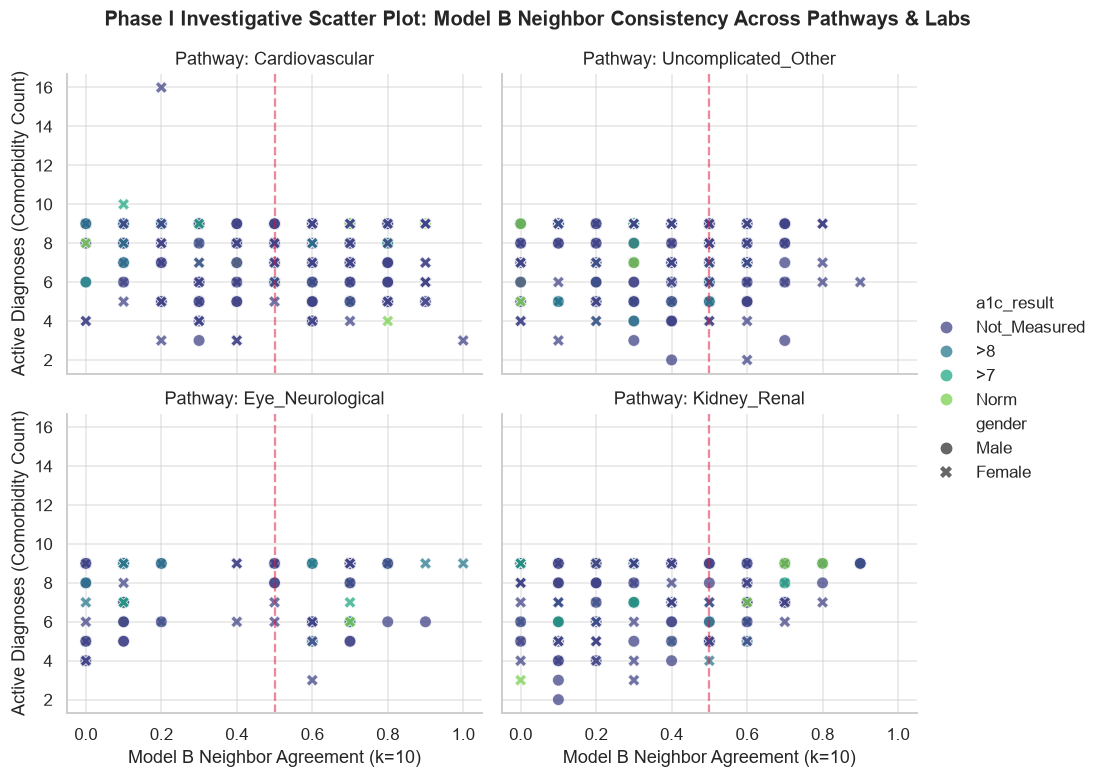

In [4]:
g = sns.relplot(
    data=df,
    x="modelB_neighbor_agreement",
    y="number_diagnoses",
    hue="a1c_result",
    style="gender",
    col="true_pathway",
    col_wrap=2,
    height=3.6,
    aspect=1.2,
    alpha=0.75,
    s=60,
    palette="viridis",
)
g.set_axis_labels("Model B Neighbor Agreement (k=10)", "Active Diagnoses (Comorbidity Count)")
g.set_titles("Pathway: {col_name}")
for ax in g.axes.flat:
    ax.axvline(0.5, color="crimson", linestyle="--", alpha=0.5, label="50% Agreement")
plt.subplots_adjust(top=0.90)
g.fig.suptitle("Phase I Investigative Scatter Plot: Model B Neighbor Consistency Across Pathways & Labs", fontsize=13, fontweight="bold")
plt.show()

---
## 3. Baseline Visualization 2: Side-by-Side Reordered Confusion Matrices
*Following Lab 02 Practical Examples (Slides 15–20):* We predict each patient's pathway via majority vote of their $k=10$ neighbors, and reorder rows/columns by error similarity (hierarchical clustering) to reveal whether confusions form clinically meaningful blocks (e.g., *Cardiovascular* $\leftrightarrow$ *Kidney_Renal*) or fail systematically on underrepresented pathways (*Eye_Neurological*).

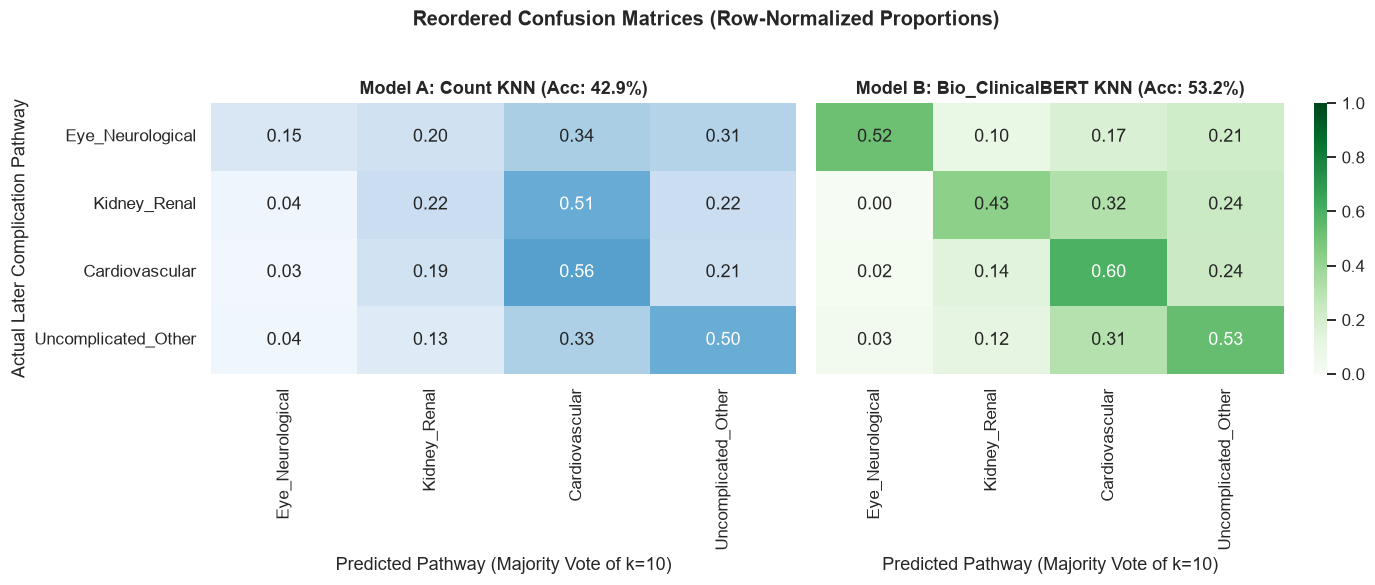

In [5]:
labels = sorted(df["true_pathway"].unique())

cm_a = pd.crosstab(df["true_pathway"], df["modelA_pred_pathway"]).reindex(index=labels, columns=labels, fill_value=0)
cm_b = pd.crosstab(df["true_pathway"], df["modelB_pred_pathway"]).reindex(index=labels, columns=labels, fill_value=0)

# Row-normalize to compare error structure across frequent and rare pathways
cm_a_norm = cm_a.div(cm_a.sum(axis=1).replace(0, 1), axis=0)
cm_b_norm = cm_b.div(cm_b.sum(axis=1).replace(0, 1), axis=0)

# Reorder rows and columns by hierarchical clustering of error similarity on Model B
sym_sim = (cm_b_norm.values + cm_b_norm.values.T) / 2.0
order_idx = leaves_list(linkage(sym_sim, method="ward"))
ordered_labels = [labels[i] for i in order_idx]

cm_a_ord = cm_a_norm.loc[ordered_labels, ordered_labels]
cm_b_ord = cm_b_norm.loc[ordered_labels, ordered_labels]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
sns.heatmap(cm_a_ord, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title(f"Model A: Count KNN (Acc: {df['modelA_is_correct'].mean():.1%})", fontweight="bold")
axes[0].set_xlabel("Predicted Pathway (Majority Vote of k=10)")
axes[0].set_ylabel("Actual Later Complication Pathway")

sns.heatmap(cm_b_ord, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title(f"Model B: Bio_ClinicalBERT KNN (Acc: {df['modelB_is_correct'].mean():.1%})", fontweight="bold")
axes[1].set_xlabel("Predicted Pathway (Majority Vote of k=10)")
axes[1].set_ylabel("")

plt.suptitle("Reordered Confusion Matrices (Row-Normalized Proportions)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## 4. Baseline Visualization 3: 2D Input-Space Projection & Failure Region Drill-Down
*Following Lab 02 Practical Examples (Slides 10–14):*  
We compute a 2D projection (UMAP if installed, otherwise PCA) strictly on **interpretable input attributes** (`age_num`, `time_in_hospital`, `num_lab_procedures`, `num_medications`, `number_diagnoses`, `prior_visits_total`, `record_completeness`, plus one-hot encoded `gender`, `race`, `a1c_result`), and color the points by:
1. **Model B Neighbor Agreement** (where in patient input space does `Bio_ClinicalBERT` fail?)
2. **Model B minus Model A Agreement** (where does `Bio_ClinicalBERT` beat or lose to the transparent Count baseline?)

C:\Users\juba9\Desktop\2026W\AI and Visualization\UE\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\juba9\Desktop\2026W\AI and Visualization\UE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


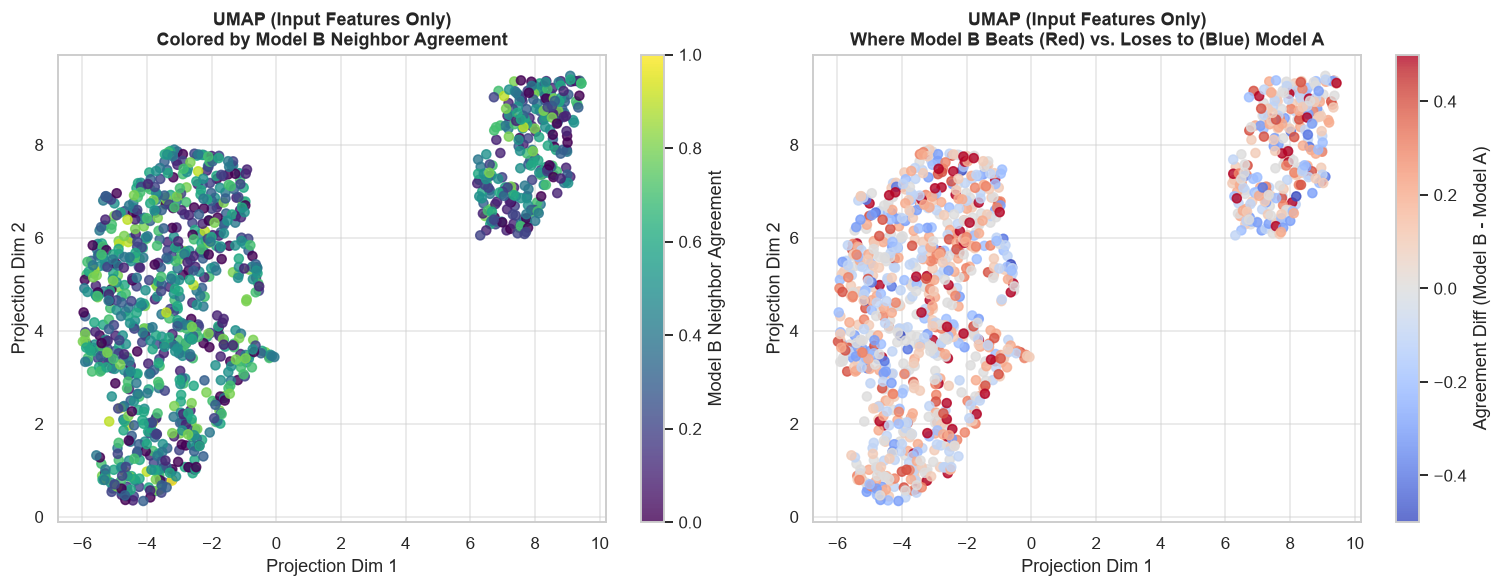

In [6]:
num_input_cols = [
    "age_num", "time_in_hospital", "num_lab_procedures",
    "num_procedures", "num_medications", "number_diagnoses",
    "prior_visits_total", "record_completeness"
]
cat_input_cols = ["gender", "race", "a1c_result", "insulin_status"]

X_num = StandardScaler().fit_transform(df[num_input_cols].values.astype(float))
X_cat = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit_transform(df[cat_input_cols])
X_input_space = np.hstack([X_num, X_cat * 0.7])

try:
    import umap
    reducer = umap.UMAP(n_neighbors=20, min_dist=0.25, random_state=42)
    coords_2d = reducer.fit_transform(X_input_space)
    proj_method = "UMAP (Input Features Only)"
except Exception:
    reducer = PCA(n_components=2, random_state=42)
    coords_2d = reducer.fit_transform(X_input_space)
    proj_method = "PCA (Input Features Only)"

df["input_proj_x"] = coords_2d[:, 0]
df["input_proj_y"] = coords_2d[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sc1 = axes[0].scatter(
    df["input_proj_x"], df["input_proj_y"],
    c=df["modelB_neighbor_agreement"], cmap="viridis", s=35, alpha=0.8
)
plt.colorbar(sc1, ax=axes[0], label="Model B Neighbor Agreement")
axes[0].set_title(f"{proj_method}\nColored by Model B Neighbor Agreement", fontweight="bold")
axes[0].set_xlabel("Projection Dim 1")
axes[0].set_ylabel("Projection Dim 2")

sc2 = axes[1].scatter(
    df["input_proj_x"], df["input_proj_y"],
    c=df["modelB_minus_modelA_agreement"], cmap="coolwarm", vmin=-0.5, vmax=0.5, s=35, alpha=0.8
)
plt.colorbar(sc2, ax=axes[1], label="Agreement Diff (Model B - Model A)")
axes[1].set_title(f"{proj_method}\nWhere Model B Beats (Red) vs. Loses to (Blue) Model A", fontweight="bold")
axes[1].set_xlabel("Projection Dim 1")
axes[1].set_ylabel("Projection Dim 2")

plt.tight_layout()
plt.show()

In [7]:
# Drill-Down Comparison: What distinguishes low-agreement failure patients (< 0.3) from high-agreement patients (>= 0.6)?
df["performance_group"] = pd.cut(
    df["modelB_neighbor_agreement"],
    bins=[-0.01, 0.30, 0.59, 1.01],
    labels=["Low Agreement (<=0.3)", "Medium (0.3-0.6)", "High Agreement (>=0.6)"]
)

summary_drilldown = df.groupby("performance_group", observed=False)[[
    "age_num", "number_diagnoses", "num_lab_procedures", "record_completeness",
    "modelB_same_sex_neighbor_ratio", "flip_sex_swap_modelB", "flip_hba1c_pert_modelB"
]].mean().round(2)

print("=== DRILL-DOWN SUMMARY BY MODEL B AGREEMENT TIER ===")
display(summary_drilldown)

=== DRILL-DOWN SUMMARY BY MODEL B AGREEMENT TIER ===


,age_num,number_diagnoses,num_lab_procedures,record_completeness,modelB_same_sex_neighbor_ratio,flip_sex_swap_modelB,flip_hba1c_pert_modelB
performance_group,,,,,,,
Low Agreement (<=0.3),64.79,7.72,42.76,0.43,0.81,6.24,3.12
Medium (0.3-0.6),65.59,7.84,41.39,0.41,0.82,6.41,3.06
High Agreement (>=0.6),67.18,7.78,41.78,0.40,0.82,6.31,2.84


---
## 5. Baseline Visualization 4: Longitudinal Admission Trajectories & Counterfactual "Neighbor Flips"
1. **Left Panel (Longitudinal Paths Over Admissions):** Connects repeat visits of the same patient (`V1 -> V2 -> V3...`) in the 2D input projection (*Projection Path Explorer*, Hinterreiter et al. 2021) to observe how neighbor agreement evolves over time.
2. **Right Panel (Counterfactual & Perturbation Sensitivity):** Shows how many of the $k=10$ neighbors flip when we apply a **Demographic Counterfactual** (`Sex Swap: Male <-> Female`, `Age +20 yrs`) vs. a **Clinical Lab Perturbation** (`HbA1c Shift`).

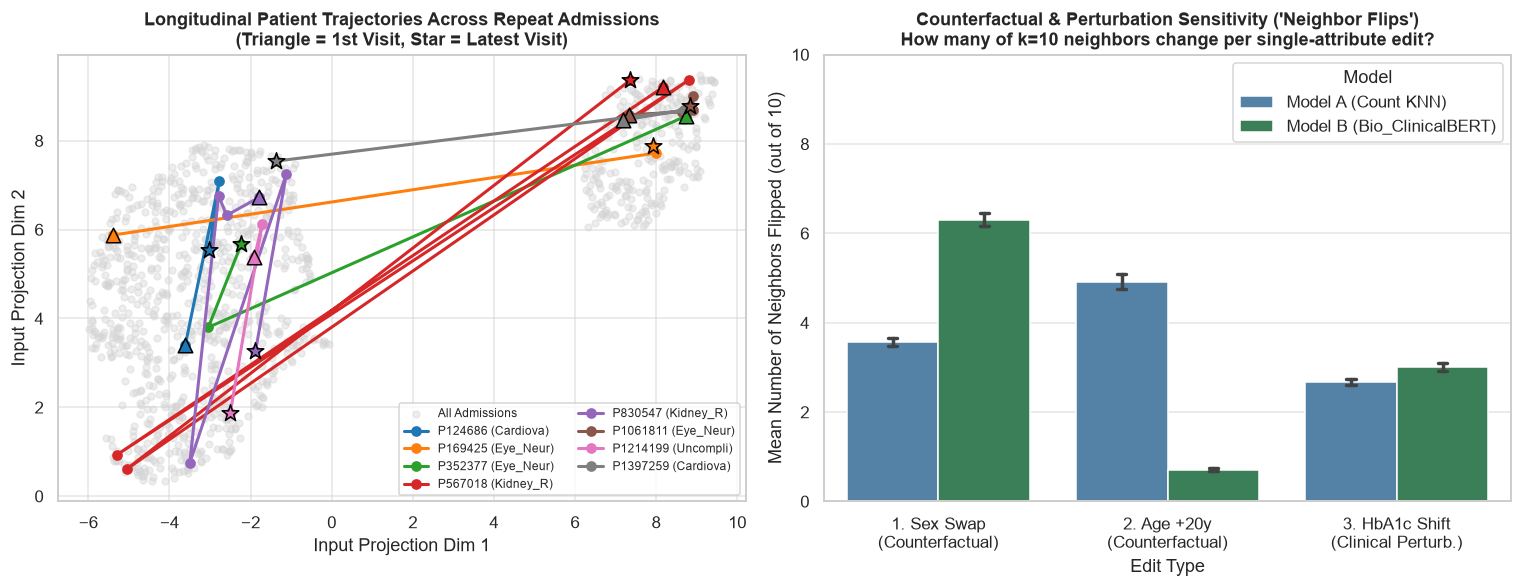

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Left Panel: Trajectory paths for sample patients with >= 3 admissions ---
axes[0].scatter(df["input_proj_x"], df["input_proj_y"], color="lightgray", s=20, alpha=0.4, label="All Admissions")
multi_visit_uids = df[df["total_patient_admissions"] >= 3]["patient_uid"].unique()[:8]
palette = sns.color_palette("tab10", len(multi_visit_uids))

for uid, color in zip(multi_visit_uids, palette):
    sub = df[df["patient_uid"] == uid].sort_values("admission_number")
    axes[0].plot(sub["input_proj_x"], sub["input_proj_y"], marker="o", linewidth=2.0, color=color, label=f"{uid} ({sub['true_pathway'].iloc[0][:8]})")
    # Mark start (V1) and end (Vn)
    axes[0].scatter(sub["input_proj_x"].iloc[0], sub["input_proj_y"].iloc[0], marker="^", s=90, color=color, edgecolor="black", zorder=5)
    axes[0].scatter(sub["input_proj_x"].iloc[-1], sub["input_proj_y"].iloc[-1], marker="*", s=130, color=color, edgecolor="black", zorder=5)

axes[0].set_title("Longitudinal Patient Trajectories Across Repeat Admissions\n(Triangle = 1st Visit, Star = Latest Visit)", fontweight="bold")
axes[0].set_xlabel("Input Projection Dim 1")
axes[0].set_ylabel("Input Projection Dim 2")
axes[0].legend(fontsize=8, loc="best", ncol=2)

# --- Right Panel: Counterfactual & Perturbation Neighbor Flip Comparison ---
flip_long = pd.DataFrame({
    "Edit Type": np.repeat(["1. Sex Swap\n(Counterfactual)", "2. Age +20y\n(Counterfactual)", "3. HbA1c Shift\n(Clinical Perturb.)"], len(df) * 2),
    "Model": np.tile(np.repeat(["Model A (Count KNN)", "Model B (Bio_ClinicalBERT)"], len(df)), 3),
    "Neighbors Flipped (out of 10)": np.concatenate([
        df["flip_sex_swap_modelA"], df["flip_sex_swap_modelB"],
        df["flip_age_shift_modelA"], df["flip_age_shift_modelB"],
        df["flip_hba1c_pert_modelA"], df["flip_hba1c_pert_modelB"],
    ])
})

sns.barplot(data=flip_long, x="Edit Type", y="Neighbors Flipped (out of 10)", hue="Model", ax=axes[1], palette=["steelblue", "seagreen"], capsize=0.08)
axes[1].set_title("Counterfactual & Perturbation Sensitivity ('Neighbor Flips')\nHow many of k=10 neighbors change per single-attribute edit?", fontweight="bold")
axes[1].set_ylabel("Mean Number of Neighbors Flipped (out of 10)")
axes[1].set_ylim(0, 10)

plt.tight_layout()
plt.show()

---
## 6. Next Steps: Splitting into Pair 1 (AI-Aided) & Pair 2 (Human-Only) for Phase I

Now that all 4 team members have reviewed this shared baseline, copy this notebook into your respective pair folders (`pair1_ai_aided/` and `pair2_human_only/`) and investigate the shared Phase I research questions in depth:

1. **Subgroup Error & Bias Analysis:**
   - Why does `Eye_Neurological` or `Kidney_Renal` get confused with `Cardiovascular`? Within those confused patients, how do lab values (`a1c_result`, `num_lab_procedures`) or `record_completeness` differ?
   - Look at `modelA_same_sex_neighbor_ratio` and `modelB_same_sex_neighbor_ratio`: does `Bio_ClinicalBERT` overly match patients by **sex or race** rather than disease pathway compared to the Count baseline?
2. **Deepening the Input-Space Projection (Drill-Down $\rightarrow$ Summarize $\rightarrow$ Annotate):**
   - Identify 2–3 specific clusters in the 2D input projection where Model B fails (or where Model A and Model B strongly disagree). Use `inspect_patient_neighbors(patient_id)` to inspect the records, and **annotate those regions directly on your chart**!
3. **Counterfactual & Trajectory Deep-Dive:**
   - Which specific patients experience the largest neighbor flips when `Sex` is swapped vs. when `HbA1c` is perturbed? Does a patient's neighbor agreement improve on later admissions (`admission_number = 2, 3...`) as their clinical history becomes more complete?